# Optimal control from zero: four problems, one idea

**QMB 6875 · Presentation 1 walkthrough**

Every problem in this notebook answers the same question:

> *What should I do **now**, knowing that today's choice changes **tomorrow**?*

We go from the easiest case to the hardest:

| # | Problem | Randomness? | How we solve it |
|---|---------|-------------|-----------------|
| 1 | When to cut a tree | no | calculus (one equation) |
| 2 | How to feed a heifer, and when to sell | no | Pontryagin's maximum principle (a whole *plan*) |
| 3 | Which offer to accept | yes | Bellman equation (closed form) |
| 4 | When the gold trader should ship | yes | Bellman equation (solved on a computer) |

Each answer is checked against an independent computer calculation, so you never have to take the algebra on faith.

**Running this in Google Colab:** run the first code cell. It clones the repo if needed .

In [1]:
import os, sys
if not os.path.exists("../src") and not os.path.exists("qmb6875-1-optimal-control"):
    # In Colab: uncomment the next line and then run this cell
    # !git clone https://github.com/ace469089/qmb6875-1-optimal-control.git
    pass
for p in ["../src", "qmb6875-1-optimal-control/src", "src"]:
    if os.path.exists(p):
        sys.path.insert(0, os.path.abspath(p))

import numpy as np
import matplotlib.pyplot as plt
from optcontrol import tree, heifer, offer, gold
np.set_printoptions(precision=4, suppress=True)
print("ready")

ready


## 1. When do you cut a tree?

Timber volume grows like $Q(T)=e^{a-b/T}$. Its **growth rate** $Q'(T)/Q(T)=b/T^2$ falls as the tree ages.
Cutting at age $T$ is worth $p\,Q(T)\,e^{-rT}$ today. Setting the derivative of the log to zero:

$$\frac{Q'(T)}{Q(T)} = r \quad\Longrightarrow\quad \frac{b}{T^2}=r \quad\Longrightarrow\quad T^*=\sqrt{b/r}=\sqrt{100/0.04}=50 \text{ years.}$$

**Rule: wait while the tree grows faster than money in the bank.**

closed form:   T* = 50.0000 years
grid search:   T* = 50.0000 years
growth rate at T*: 0.0400  (interest rate = 0.04)
second derivative of log PV at T*: -0.001600 (< 0, so a maximum)

If the land is replanted forever (Faustmann): T* = 45.83 years


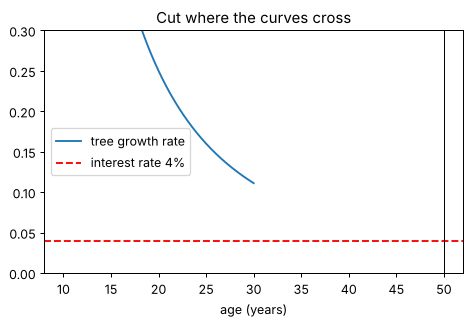

In [2]:
T_star = tree.fisher_rotation()
print(f"closed form:   T* = {T_star:.4f} years")

# Independent check: evaluate present value on a fine grid and take the best
T = np.linspace(10, 150, 140_001)
pv = tree.present_value(T)
print(f"grid search:   T* = {T[np.argmax(pv)]:.4f} years")
print(f"growth rate at T*: {tree.growth_rate(T_star):.4f}  (interest rate = {tree.R})")
print(f"second derivative of log PV at T*: {tree.second_derivative_log_pv(T_star):.6f} (< 0, so a maximum)")
print(f"\nIf the land is replanted forever (Faustmann): T* = {tree.faustmann_rotation():.2f} years")

plt.figure(figsize=(6, 3.5))
plt.plot(T[:20000], tree.growth_rate(T[:20000]), label="tree growth rate")
plt.axhline(tree.R, ls="--", color="red", label="interest rate 4%")
plt.axvline(T_star, color="k", lw=0.8)
plt.ylim(0, 0.3); plt.xlabel("age (years)"); plt.legend(); plt.title("Cut where the curves cross")

## 2. Feeding a heifer: choosing a whole plan

Now the choice is not one number but a **feeding schedule** $f(t)$ for every day.

* weight grows: $\dot W = a\sqrt{f} - mW$ (diminishing returns to feed; heavier animals burn more just to stay the same size)
* profit: $\;J = p\,W(T)\,e^{-rT} - \int_0^T c\,f(t)\,e^{-rt}\,dt$

**Pontryagin's trick:** give every pound a price tag $\lambda(t)$ (its *shadow value*). Then each day:

$$\underbrace{c\,e^{-rt}}_{\text{cost of a scoop}} = \underbrace{\lambda(t)\,\frac{a}{2\sqrt f}}_{\text{value of the weight it adds}}, \qquad \dot\lambda = m\lambda, \qquad \lambda(T)=p\,e^{-rT}.$$

Solving gives $f^*(t) = \big(\tfrac{a p}{2c}\big)^2 e^{-2(r+m)(T-t)}$: **feed lightly early and heavily just before the sale.**

Below we compare that formula to a computer that knows *no calculus*: it simply tries 40 feed levels and climbs uphill.

optimal sale day: 239.3  (~7.9 months)
sale weight:      942 lb
feed on day 0:    8.3 lb/day
feed on sale day: 26.1 lb/day
profit (PV):      $1,074.51  vs selling today $900.00

brute-force profit: $1,074.50
largest gap between formula and optimizer: 0.00040 lb/day


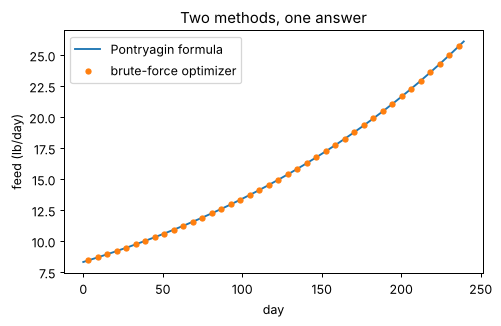

In [3]:
T_sale = heifer.optimal_sale_day()
print(f"optimal sale day: {T_sale:.1f}  (~{T_sale/30.44:.1f} months)")
print(f"sale weight:      {heifer.optimal_weight(T_sale, T_sale):.0f} lb")
print(f"feed on day 0:    {heifer.optimal_feed(0, T_sale):.1f} lb/day")
print(f"feed on sale day: {heifer.optimal_feed(T_sale, T_sale):.1f} lb/day")
print(f"profit (PV):      ${heifer.profit(T_sale):,.2f}  vs selling today ${heifer.DEFAULT.p*heifer.DEFAULT.W0:,.2f}")

mid, f_num, J_num = heifer.solve_numerically(T_sale, N=40)
print(f"\nbrute-force profit: ${J_num:,.2f}")
print(f"largest gap between formula and optimizer: {np.max(np.abs(f_num - heifer.optimal_feed(mid, T_sale))):.5f} lb/day")

t = np.linspace(0, T_sale, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(t, heifer.optimal_feed(t, T_sale), label="Pontryagin formula")
plt.plot(mid, f_num, "o", ms=4, label="brute-force optimizer")
plt.xlabel("day"); plt.ylabel("feed (lb/day)"); plt.legend(); plt.title("Two methods, one answer")

## 3. Which offer should you accept? (randomness enters)

Each period an offer $w\sim\text{Uniform}(0,1)$ arrives. Accept and you are paid $w$; reject and you wait one period ($\beta=0.9$).
$V$ = value of waiting. If you wait, next period you take the better of the new offer and waiting again:

$$V=\beta\,E[\max(w,V)]=\beta\,\frac{1+V^2}{2}\quad\Longrightarrow\quad V^*=\frac{1-\sqrt{1-\beta^2}}{\beta}=0.627.$$

**Policy: accept any offer of at least 0.627.** That single cutoff is a *control-limit policy*.

In [4]:
V_star = offer.reservation_value(0.9)
V_vi, path = offer.value_iteration(0.9, V0=0.0)
print(f"closed form:      V* = {V_star:.6f}")
print(f"value iteration:  V* = {V_vi:.6f}  ({len(path)-1} iterations from V0 = 0)")
print("first iterates:  ", np.round(path[:7], 4))
print("deadline cutoffs:", np.round(offer.finite_horizon_cutoffs(7), 4), " <- identical!")

mean, se = offer.simulate_policy(V_star)
print(f"\nsimulated value of 'accept if w >= {V_star:.3f}': {mean:.4f} +/- {1.96*se:.4f}")
for c in [0.3, 0.5, 0.75, 0.9]:
    print(f"   cutoff {c:.2f} instead: {offer.simulate_policy(c)[0]:.4f}   (worse)")

closed form:      V* = 0.626789
value iteration:  V* = 0.626789  (38 iterations from V0 = 0)
first iterates:   [0.     0.45   0.5411 0.5818 0.6023 0.6132 0.6192]
deadline cutoffs: [0.     0.45   0.5411 0.5818 0.6023 0.6132 0.6192]  <- identical!

simulated value of 'accept if w >= 0.627': 0.6266 +/- 0.0009
   cutoff 0.30 instead: 0.5609   (worse)
   cutoff 0.50 instead: 0.6135   (worse)
   cutoff 0.75 instead: 0.6056   (worse)
   cutoff 0.90 instead: 0.4496   (worse)


## 4. The gold trader (the professor's capstone example)

State $s_t$ = New York premium on an ounce, an AR(1): $s_{t+1}=\mu+\rho(s_t-\mu)+\sigma\varepsilon$.
Sell: get $s-K$. Hold: pay $h$ this week (interest on the money tied up + risk of loss), discount by $\beta$.

$$V(s)=\max\{\,s-K,\;-h+\beta\,E[V(s')\mid s]\,\}$$

No pencil-and-paper solution exists, so we discretize $s$ (Tauchen's method) and run value iteration.

In [5]:
out = gold.solve()
p = gold.DEFAULT
print(f"weekly holding cost h = ${p.h:.2f}/oz,  weekly discount beta = {p.beta:.5f}")
print(f"optimal cutoff s* = ${out['cutoff']:.2f}/oz   ({out['iterations']} value-iteration steps)")
print(f"same cutoff on a 4x finer grid: ${gold.solve(n=801)['cutoff']:.2f}/oz")

print("\nHow the cutoff C(r, F, K) responds:")
for row in gold.comparative_statics():
    print(f"   {row['parameter']:>11} = {row['value']:<6}  ->  s* = {row['cutoff']:7.2f}")

print("\nSimulated value of different selling rules (start in a typical week):")
for name, c in [("sell immediately", -np.inf), ("wait for the average", p.mu),
                ("optimal", out["cutoff"]), ("too picky (+$30)", out["cutoff"] + 30)]:
    m, se, w = gold.simulate(cutoff=c)
    print(f"   {name:<22} value ${m:6.2f} +/- {1.96*se:.2f}   mean wait {w:4.1f} weeks")

weekly holding cost h = $2.89/oz,  weekly discount beta = 0.99904
optimal cutoff s* = $50.49/oz   (196 value-iteration steps)
same cutoff on a 4x finer grid: $50.49/oz

How the cutoff C(r, F, K) responds:
             r = 0.02    ->  s* =   68.63
             r = 0.05    ->  s* =   50.49
             r = 0.1     ->  s* =   29.55
             r = 0.2     ->  s* =   -2.09
             K = 10.0    ->  s* =   50.35
             K = 25.0    ->  s* =   50.49
             K = 40.0    ->  s* =   50.63
         sigma = 10.0    ->  s* =   32.93
         sigma = 20.0    ->  s* =   50.49
         sigma = 40.0    ->  s* =   96.89
           rho = 0.5     ->  s* =   53.11
           rho = 0.8     ->  s* =   50.49
           rho = 0.95    ->  s* =   19.78
   loss_annual = 0.0     ->  s* =   55.72
   loss_annual = 0.01    ->  s* =   50.49
   loss_annual = 0.05    ->  s* =   32.85
   loss_annual = 0.2     ->  s* =  -20.03

Simulated value of different selling rules (start in a typical week):
   sell im

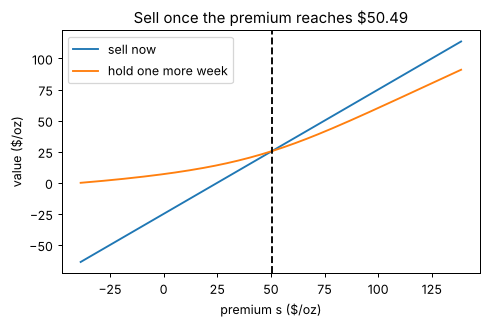

In [6]:
g, keep = out["grid"], (out["grid"] > -40) & (out["grid"] < 140)
plt.figure(figsize=(6, 3.5))
plt.plot(g[keep], out["sell"][keep], label="sell now")
plt.plot(g[keep], out["hold"][keep], label="hold one more week")
plt.axvline(out["cutoff"], ls="--", color="k")
plt.xlabel("premium s ($/oz)"); plt.ylabel("value ($/oz)"); plt.legend()
plt.title(f"Sell once the premium reaches ${out['cutoff']:.2f}")

## Try it yourself

1. Change the interest rate in `tree.fisher_rotation(b=100, r=0.08)`. Why does the rotation get shorter?
2. Make feed more expensive: `heifer.optimal_sale_day(heifer.HeiferParams(c=0.20))`. What happens to the sale date and why?
3. Set `beta=0.99` in `offer.reservation_value`. Explain the new cutoff in one sentence.
4. Raise shipping cost `K` in `gold.GoldParams(K=60)` and solve. Why does the cutoff barely move, while a higher weekly cost (via `r`) moves it a lot? (Answer in `docs/FAQ.md`.)